# 4.0 - Scoring the Live Base & BI Dashboard Data
**Week 4** | Produces the tables that Power BI / Tableau connect to (`data/processed/`) and the final report figures.

Features are rebuilt as of **2026-01-01** (day after the last order) and the models fitted on the *earlier* snapshot are only **applied** - never re-fitted - so predictions are genuinely forward-looking.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")
from src.modeling import predict as P
tx = pd.read_csv(config.DATA_INTERIM / 'transactions_clean.csv', parse_dates=['order_date'])
customers = pd.read_csv(config.DATA_RAW / 'customers.csv', parse_dates=['signup_date'])
scoring_date = (pd.Timestamp(config.END_DATE) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
seg_m, names_m, churn_m = P.load_models()
scores = P.score_customers(tx, customers, scoring_date, seg_m, names_m, churn_m)
scores.to_csv(config.DATA_PROCESSED / 'customer_scores_for_bi.csv', index=False)
print(scoring_date, scores.shape); scores[['customer_id','segment','recency_days','frequency','monetary','churn_probability','risk_tier']].head()

2026-01-01 (5000, 25)


,customer_id,segment,recency_days,frequency,monetary,churn_probability,risk_tier
0,10001,Hibernating,509,1,21.070,0.997396,High
1,10002,Hibernating,587,1,297.954,0.995426,High
2,10003,Hibernating,404,1,666.485,0.995948,High
3,10004,Hibernating,219,1,105.370,0.968995,High
4,10005,Champions,4,35,8890.471,0.065523,Low


In [2]:
tx['month'] = tx.order_date.dt.to_period('M').dt.to_timestamp()
tx['segment'] = tx.customer_id.map(scores.set_index('customer_id').segment)
mrs = tx.groupby(['month','segment'], as_index=False).agg(revenue=('line_value','sum'), orders=('order_id','nunique'))
mrs.to_csv(config.DATA_PROCESSED / 'monthly_revenue_by_segment.csv', index=False)
print('Total revenue:', f'{tx.line_value.sum():,.0f}')

Total revenue: 9,034,415


## KPI snapshot

In [3]:
kpi = scores.groupby('segment').agg(customers=('customer_id','size'), revenue=('monetary','sum'), avg_churn_prob=('churn_probability','mean'), high_risk=('risk_tier', lambda s: (s=='High').sum()))
kpi['pct_revenue'] = 100*kpi.revenue/kpi.revenue.sum()
kpi.round(2)

,customers,revenue,avg_churn_prob,high_risk,pct_revenue
segment,,,,,
At Risk,1284,1969236.22,0.76,937,21.80
Champions,1167,6058513.78,0.17,16,67.06
Hibernating,2052,500724.52,0.95,1981,5.54
Potential Loyalists,497,505940.31,0.32,4,5.60


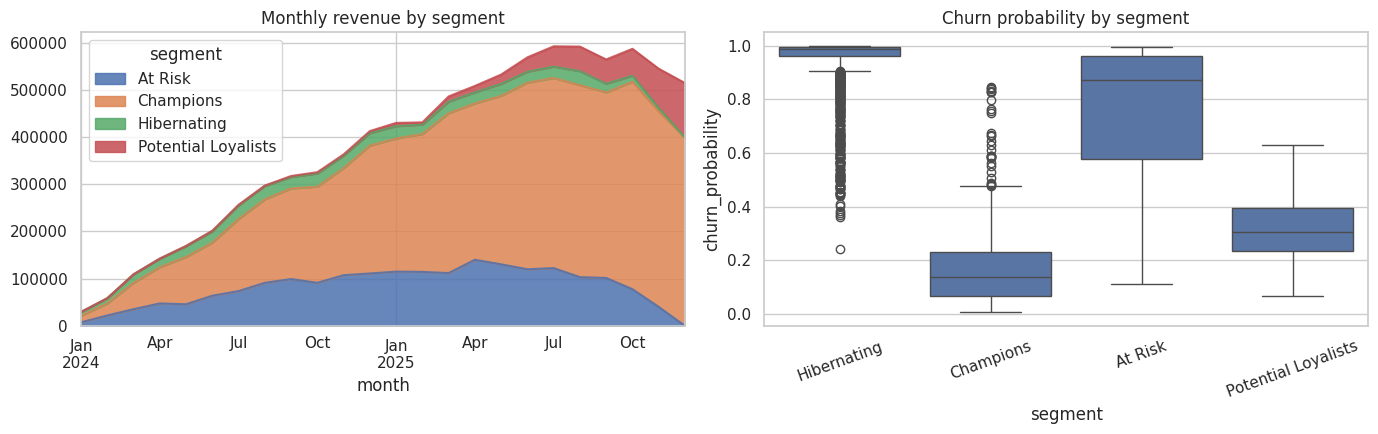

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
piv = mrs.pivot(index='month', columns='segment', values='revenue').fillna(0); piv.plot.area(ax=ax[0], alpha=.85, title='Monthly revenue by segment')
sns.boxplot(data=scores, x='segment', y='churn_probability', ax=ax[1]); ax[1].set_title('Churn probability by segment'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); save('13_revenue_and_risk_by_segment.png'); plt.show()

## High-Risk Churn list (win-back targets)
Defined as **still-recent customers (last order <= 180 days ago) with HIGH churn risk** (p >= 0.6), ranked by expected revenue at risk. Customers silent for a long time are effectively already lost and are handled by cheap automated flows instead.

In [5]:
wb = scores[scores.is_winback_target].sort_values('revenue_at_risk', ascending=False)
wb[['customer_id','segment','recency_days','frequency','monetary','churn_probability','revenue_at_risk','recommended_action']].head(15).round(2)

,customer_id,segment,recency_days,frequency,monetary,churn_probability,revenue_at_risk,recommended_action
4641,14642,Champions,172,30,9525.00,0.83,4096.46,"Reward and retain: VIP early access, loyalty t..."
3207,13208,Champions,117,31,10661.58,0.66,4058.98,"Reward and retain: VIP early access, loyalty t..."
2241,12242,Champions,157,32,10102.46,0.75,3987.96,"Reward and retain: VIP early access, loyalty t..."
472,10473,At Risk,137,8,4167.78,0.74,3835.62,Win back before they lapse: personalised 'we m...
2146,12147,Champions,175,26,9728.21,0.75,3720.71,"Reward and retain: VIP early access, loyalty t..."
1121,11122,At Risk,113,4,2731.66,0.62,3577.16,Win back before they lapse: personalised 'we m...
2069,12070,At Risk,90,3,2087.73,0.60,3400.28,Win back before they lapse: personalised 'we m...
4990,14991,At Risk,132,11,4138.15,0.72,3307.89,Win back before they lapse: personalised 'we m...
3057,13058,At Risk,154,12,4685.12,0.73,2936.25,Win back before they lapse: personalised 'we m...
114,10115,At Risk,111,12,3645.10,0.62,2684.01,Win back before they lapse: personalised 'we m...


In [6]:
wb[['customer_id','segment','city','top_channel','recency_days','frequency','monetary','churn_probability','revenue_at_risk','recommended_action']].to_csv(config.DATA_PROCESSED / 'high_risk_churn_list.csv', index=False)
print(len(wb), 'win-back targets exported | revenue at risk:', f'{wb.revenue_at_risk.sum():,.0f}')

639 win-back targets exported | revenue at risk: 492,230


## Files ready for Power BI / Tableau
| File | Use |
|---|---|
| `customer_scores_for_bi.csv` | one row per customer: RFM, segment, churn probability, tier, action |
| `monthly_revenue_by_segment.csv` | revenue trend & segment breakdown |
| `high_risk_churn_list.csv` | the 'High-Risk Churn' table |
| `segment_summary.csv` | segment sizes & playbook |

Build steps: see `dashboard/POWERBI_BUILD_GUIDE.md`. A ready-to-open interactive version is in `dashboard/churn_dashboard.html`.